# Réplica: *Unmasking Banking Fraud* (Nobel et al., 2024)

**Artículo replicado:** Nobel, S. M. N., Sultana, S., Singha, S. P., Chaki, S., Mahi, M. J. N., Jan, T., Barros, A., & Whaiduzzaman, M. (2024). *Unmasking Banking Fraud: Unleashing the Power of Machine Learning and Explainable AI (XAI) on Imbalanced Data*. **Information, 15**(6), 298. https://doi.org/10.3390/info15060298

**Autora de la réplica:** Fátima Abregú

**Objetivo:** reproducir el flujo del artículo (PaySim → preprocesamiento → SMOTE → 4 modelos → métricas → SHAP y LIME) y comparar mis resultados con los reportados por los autores.

| Fase | Qué hace este notebook |
|---|---|
| 1. Datos | Descarga PaySim desde Kaggle y lo explora |
| 2. Preparación | LabelEncoder, MinMaxScaler, división 80/20, SMOTE (solo en entrenamiento) |
| 3. Modelado | Regresión logística, XGBoost, Árbol de decisión, SVM lineal |
| 4. Evaluación y XAI | Accuracy, precisión, recall, F1, AUC; SHAP y LIME |

> En Colab: **Entorno de ejecución → Ejecutar todo**. Tiempo aproximado: 10–15 minutos.

## 0. Instalación y librerías

In [ ]:
!pip install -q xgboost imbalanced-learn shap lime kagglehub

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEMILLA = 42          # misma semilla que usa el artículo (random_state = 42)
np.random.seed(SEMILLA)

## 1. Datos — PaySim

Dataset sintético de dinero móvil (Kaggle: *Synthetic Financial Datasets For Fraud Detection*). Se descarga con `kagglehub`, que no requiere cuenta para datasets públicos.

Si la descarga falla, descarga el CSV desde https://www.kaggle.com/datasets/ealaxi/paysim1, súbelo a Colab (ícono de carpeta) y cambia `ARCHIVO` por su ruta.

In [ ]:
import kagglehub
ruta = kagglehub.dataset_download("ealaxi/paysim1")
ARCHIVO = glob.glob(os.path.join(ruta, "*.csv"))[0]
print("Archivo:", ARCHIVO)

Using Colab cache for faster access to the 'paysim1' dataset.
Archivo: /kaggle/input/paysim1/PS_20174392719_1491204439457_log.csv


In [ ]:
df = pd.read_csv(ARCHIVO)
print("Filas x columnas:", df.shape)
df.head()

Filas x columnas: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
# ¿Qué tan desbalanceados están los datos?
conteo = df["isFraud"].value_counts()
print(conteo)
print(f"\nPorcentaje de fraude: {100 * conteo[1] / len(df):.3f} %")

# ¿En qué tipos de transacción ocurre el fraude?
print("\nFraudes por tipo de transacción:")
print(df.groupby("type")["isFraud"].sum())

isFraud
0    6354407
1       8213
Name: count, dtype: int64

Porcentaje de fraude: 0.129 %

Fraudes por tipo de transacción:
type
CASH_IN        0
CASH_OUT    4116
DEBIT          0
PAYMENT        0
TRANSFER    4097
Name: isFraud, dtype: int64


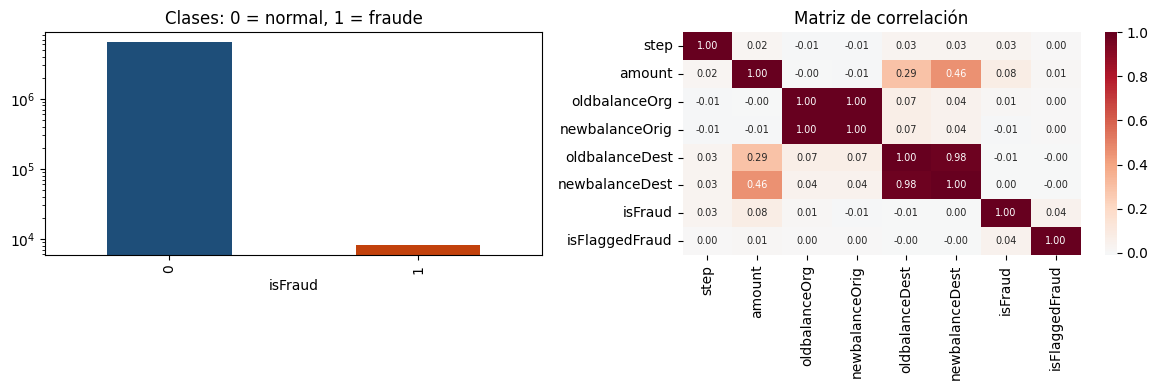

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["isFraud"].value_counts().plot(kind="bar", ax=ax[0], color=["#1E4E79", "#C2410C"])
ax[0].set_title("Clases: 0 = normal, 1 = fraude"); ax[0].set_yscale("log")
sns.heatmap(df.select_dtypes("number").corr(), cmap="RdBu_r", center=0, ax=ax[1], annot=True, fmt=".2f", annot_kws={"size": 7})
ax[1].set_title("Matriz de correlación")
plt.tight_layout(); plt.show()

### Muestra estratificada

El dataset completo tiene ≈6,3 millones de filas. Para que el notebook corra en Colab gratuito se usa una **muestra estratificada** (mantiene el mismo % de fraude). Es una decisión de la réplica que debe mencionarse en la exposición. Puedes subir `FRACCION` a 1.0 si tienes tiempo y memoria.

In [ ]:
FRACCION = 0.10
if FRACCION < 1.0:
    df, _ = train_test_split(df, train_size=FRACCION, stratify=df["isFraud"], random_state=SEMILLA)
print("Filas usadas:", len(df), "| fraudes:", int(df["isFraud"].sum()))

Filas usadas: 636262 | fraudes: 821


## 2. Preparación (igual que el artículo)

- **LabelEncoder** para las 3 variables categóricas: `type`, `nameOrig`, `nameDest`.
- **MinMaxScaler** para las variables numéricas (rango 0–1).
- División **80 % entrenamiento / 20 % prueba**, estratificada.
- **SMOTE** para balancear. ⚠️ Se aplica **solo al entrenamiento**: si se aplicara antes de dividir, ejemplos sintéticos "parecidos" al conjunto de prueba se filtrarían al entrenamiento (fuga de datos) y las métricas saldrían infladas. El artículo no aclara este punto.

In [ ]:
y = df["isFraud"].values
X = df.drop(columns=["isFraud"]).copy()

categoricas = ["type", "nameOrig", "nameDest"]
for col in categoricas:
    X[col] = LabelEncoder().fit_transform(X[col].astype(str))

print("Variables usadas:", list(X.columns))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)

escalador = MinMaxScaler().fit(X_train)            # se ajusta solo con entrenamiento
X_train = pd.DataFrame(escalador.transform(X_train), columns=X.columns)
X_test  = pd.DataFrame(escalador.transform(X_test),  columns=X.columns)

print("Entrenamiento:", X_train.shape, "| fraudes:", y_train.sum())
print("Prueba:       ", X_test.shape,  "| fraudes:", y_test.sum())

Variables usadas: ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFlaggedFraud']
Entrenamiento: (509009, 10) | fraudes: 657
Prueba:        (127253, 10) | fraudes: 164


In [ ]:
inicio = time.time()
X_train_bal, y_train_bal = SMOTE(random_state=SEMILLA).fit_resample(X_train, y_train)
print(f"Después de SMOTE: {X_train_bal.shape} en {time.time()-inicio:.0f} s")
print(pd.Series(y_train_bal).value_counts())

Después de SMOTE: (1016704, 10) en 0 s
0    508352
1    508352
Name: count, dtype: int64


## 3. Modelado — los 4 modelos del artículo

| Modelo | Configuración del artículo |
|---|---|
| Regresión logística | random_state = 42 |
| XGBoost | 341 árboles, profundidad 7, subsample 0.9, learning rate 0.001, gamma 0.5 |
| Árbol de decisión | criterio entropía |
| SVM | kernel lineal, C = 1.0 |

Nota: para la SVM se usa `LinearSVC`, que es la misma SVM de kernel lineal pero optimizada para muchos datos (`SVC(kernel="linear")` tardaría horas con más de un millón de filas).

In [ ]:
modelos = {
    "Regresión logística": LogisticRegression(random_state=SEMILLA, max_iter=1000),
    "XGBoost": XGBClassifier(n_estimators=341, max_depth=7, subsample=0.9, learning_rate=0.001,
                             gamma=0.5, random_state=SEMILLA, n_jobs=-1, eval_metric="logloss"),
    "Árbol de decisión": DecisionTreeClassifier(criterion="entropy", random_state=SEMILLA),
    "SVM lineal": LinearSVC(C=1.0, random_state=SEMILLA, dual=False),
}

def puntaje(modelo, X):
    # probabilidad (o distancia a la frontera, en la SVM) de ser fraude, para el AUC
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)

def evaluar(nombre, modelo, X, y):
    pred = modelo.predict(X)
    return {"Modelo": nombre,
            "Accuracy": accuracy_score(y, pred),
            "Precisión": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred),
            "F1": f1_score(y, pred),
            "AUC": roc_auc_score(y, puntaje(modelo, X))}

resultados = []
for nombre, modelo in modelos.items():
    inicio = time.time()
    modelo.fit(X_train_bal, y_train_bal)
    resultados.append(evaluar(nombre, modelo, X_test, y_test))
    print(f"{nombre}: entrenado en {time.time()-inicio:.0f} s")

mis_resultados = pd.DataFrame(resultados).set_index("Modelo").round(4)
mis_resultados

Regresión logística: entrenado en 13 s
XGBoost: entrenado en 37 s
Árbol de decisión: entrenado en 17 s
SVM lineal: entrenado en 7 s


,Accuracy,Precisión,Recall,F1,AUC
Modelo,,,,,
Regresión logística,0.9310,0.0141,0.7622,0.0277,0.9361
XGBoost,0.9885,0.0957,0.9390,0.1737,0.9876
Árbol de decisión,0.9990,0.5665,0.9085,0.6979,0.9538
SVM lineal,0.9730,0.0373,0.8049,0.0714,0.9671


## 4. Evaluación — mis resultados frente al artículo

Valores del artículo (con SMOTE). Precisión, recall y F1 se reportan para la clase fraude.

In [ ]:
articulo = pd.DataFrame({
    "Modelo":    ["Regresión logística", "XGBoost", "Árbol de decisión", "SVM lineal"],
    "Accuracy":  [0.9899, 0.9988, 0.9896, 0.9691],
    "Precisión": [0.92, 0.96, 0.87, 0.64],
    "Recall":    [0.86, 0.88, 0.85, 0.36],
    "F1":        [0.89, 0.92, 0.86, 0.48],
    "AUC":       [0.94, 1.00, 0.84, np.nan],
}).set_index("Modelo")

comparacion = pd.concat({"Artículo": articulo, "Mi réplica": mis_resultados}, axis=1)
comparacion = comparacion.swaplevel(axis=1).sort_index(axis=1, level=0)
comparacion.round(3)

AUC            Accuracy                  F1  \
                    Artículo Mi réplica Artículo Mi réplica Artículo   
Modelo                                                                 
Regresión logística     0.94      0.936    0.990      0.931     0.89   
XGBoost                 1.00      0.988    0.999      0.988     0.92   
Árbol de decisión       0.84      0.954    0.990      0.999     0.86   
SVM lineal               NaN      0.967    0.969      0.973     0.48   

                               Precisión              Recall             
                    Mi réplica  Artículo Mi réplica Artículo Mi réplica  
Modelo                                                                   
Regresión logística      0.028      0.92      0.014     0.86      0.762  
XGBoost                  0.174      0.96      0.096     0.88      0.939  
Árbol de decisión        0.698      0.87      0.566     0.85      0.908  
SVM lineal               0.071      0.64      0.037     0.36      0.805

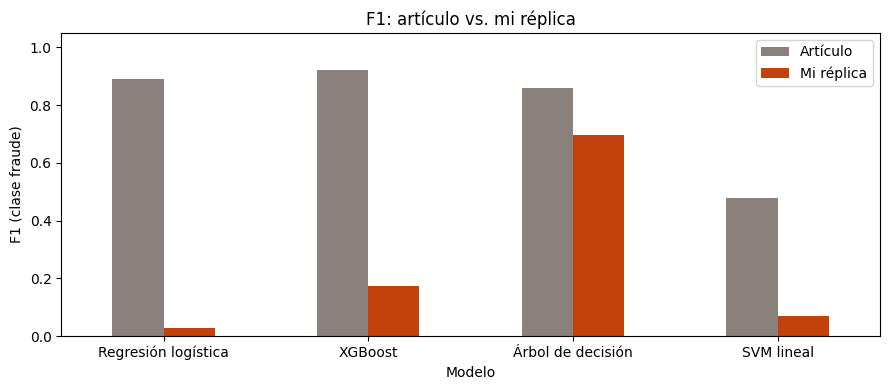

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
pd.DataFrame({"Artículo": articulo["F1"], "Mi réplica": mis_resultados["F1"]}).plot(
    kind="bar", ax=ax, color=["#8A817C", "#C2410C"])
ax.set_ylabel("F1 (clase fraude)"); ax.set_ylim(0, 1.05); ax.set_title("F1: artículo vs. mi réplica")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

Mejor modelo en mi réplica: Árbol de decisión


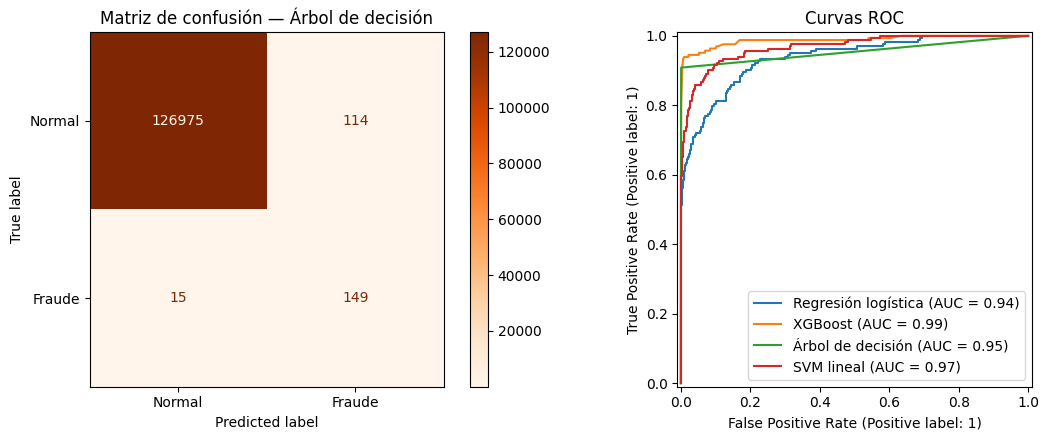

In [ ]:
# Matriz de confusión y curva ROC del mejor modelo según mi F1
mejor = mis_resultados["F1"].idxmax()
print("Mejor modelo en mi réplica:", mejor)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_estimator(modelos[mejor], X_test, y_test, ax=ax[0], cmap="Oranges",
                                      display_labels=["Normal", "Fraude"])
ax[0].set_title(f"Matriz de confusión — {mejor}")
for nombre, modelo in modelos.items():
    RocCurveDisplay.from_predictions(y_test, puntaje(modelo, X_test), name=nombre, ax=ax[1])
ax[1].set_title("Curvas ROC")
plt.tight_layout(); plt.show()

### Efecto del balanceo (Tabla 5 del artículo)

El artículo compara XGBoost **sin balanceo**, con **undersampling** y con **SMOTE**. Aquí se repite el experimento.

In [ ]:
balanceos = {
    "Sin balanceo": (X_train, y_train),
    "Undersampling": RandomUnderSampler(random_state=SEMILLA).fit_resample(X_train, y_train),
    "SMOTE": (X_train_bal, y_train_bal),
}
filas = []
for nombre, (Xb, yb) in balanceos.items():
    m = XGBClassifier(**modelos["XGBoost"].get_params())
    m.fit(Xb, yb)
    filas.append(evaluar(nombre, m, X_test, y_test))
tabla_balanceo = pd.DataFrame(filas).set_index("Modelo").rename_axis("Técnica (XGBoost)")
tabla_balanceo["Accuracy artículo"] = [0.9597, 0.9741, 0.9988]
tabla_balanceo.round(4)

,Accuracy,Precisión,Recall,F1,AUC,Accuracy artículo
Técnica (XGBoost),,,,,,
Sin balanceo,0.9987,0.0000,0.0000,0.0000,0.9893,0.9597
Undersampling,0.9691,0.0382,0.9512,0.0734,0.9822,0.9741
SMOTE,0.9885,0.0957,0.9390,0.1737,0.9876,0.9988


### Extensión: XGBoost con otra tasa de aprendizaje

Con `learning_rate = 0.001` y 341 árboles, el modelo aprende muy poco a poco: sus probabilidades se quedan cerca de 0,5 y puede marcar muchas transacciones normales como fraude (precisión baja). Aquí se prueba un valor más habitual (0.1) para comparar. Es un aporte propio, no parte del artículo.

In [ ]:
xgb_ajustado = XGBClassifier(**{**modelos["XGBoost"].get_params(), "learning_rate": 0.1})
xgb_ajustado.fit(X_train_bal, y_train_bal)
pd.DataFrame([evaluar("XGBoost (lr = 0.001, artículo)", modelos["XGBoost"], X_test, y_test),
              evaluar("XGBoost (lr = 0.1, ajustado)", xgb_ajustado, X_test, y_test)]).set_index("Modelo").round(4)

,Accuracy,Precisión,Recall,F1,AUC
Modelo,,,,,
"XGBoost (lr = 0.001, artículo)",0.9885,0.0957,0.9390,0.1737,0.9876
"XGBoost (lr = 0.1, ajustado)",0.9990,0.5686,0.8841,0.6921,0.9961


## 5. Explicabilidad (XAI)

- **SHAP**: cuánto aporta cada variable a la predicción, para todo el modelo (explicación global).
- **LIME**: por qué el modelo clasificó **una** transacción concreta como fraude (explicación local).

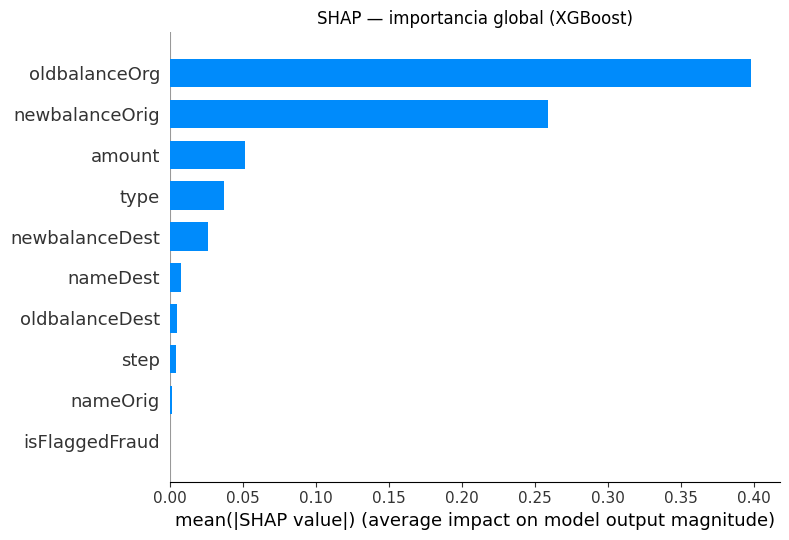

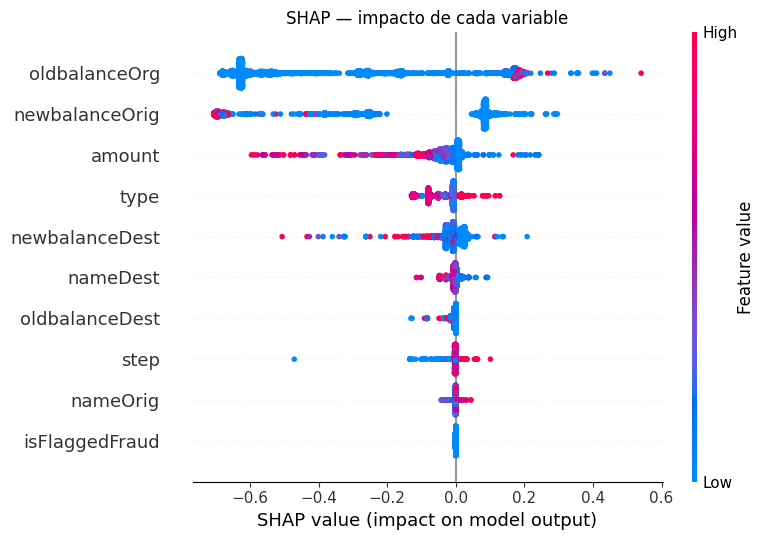

In [ ]:
import shap
xgb = modelos["XGBoost"]
muestra = X_test.sample(n=min(3000, len(X_test)), random_state=SEMILLA)
explicador = shap.TreeExplainer(xgb)
valores_shap = explicador.shap_values(muestra)

shap.summary_plot(valores_shap, muestra, plot_type="bar", show=False)
plt.title("SHAP — importancia global (XGBoost)"); plt.tight_layout(); plt.show()

shap.summary_plot(valores_shap, muestra, show=False)
plt.title("SHAP — impacto de cada variable"); plt.tight_layout(); plt.show()

Probabilidad de fraude según XGBoost: 0.6424


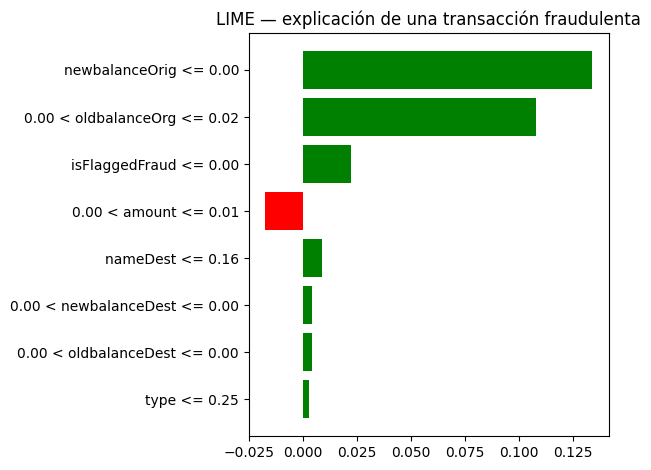

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

explicador_lime = LimeTabularExplainer(
    training_data=X_train_bal.sample(n=20000, random_state=SEMILLA).values,
    feature_names=list(X.columns), class_names=["Normal", "Fraude"],
    mode="classification", random_state=SEMILLA)

# Se explica una transacción fraudulenta real del conjunto de prueba
i = np.where(y_test == 1)[0][0]
exp = explicador_lime.explain_instance(X_test.iloc[i].values, xgb.predict_proba, num_features=8)
print("Probabilidad de fraude según XGBoost:", round(xgb.predict_proba(X_test.iloc[[i]])[0, 1], 4))
exp.as_pyplot_figure(); plt.title("LIME — explicación de una transacción fraudulenta")
plt.tight_layout(); plt.show()

## 6. Validación cruzada (opcional)

El artículo reporta validación cruzada de 10 particiones. Aquí se hace con SMOTE **dentro** de cada partición (pipeline), sobre una submuestra para que no tarde demasiado.

In [ ]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

if len(X_train) > 100000:
    sub_X, _, sub_y, _ = train_test_split(X_train, y_train, train_size=100000,
                                          stratify=y_train, random_state=SEMILLA)
else:
    sub_X, sub_y = X_train, y_train
pipe = Pipeline([("smote", SMOTE(random_state=SEMILLA)),
                 ("xgb", XGBClassifier(**modelos["XGBoost"].get_params()))])
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
f1_cv = cross_val_score(pipe, sub_X, sub_y, cv=cv, scoring="f1", n_jobs=-1)
print("F1 por partición:", np.round(f1_cv, 3))
print(f"F1 promedio: {f1_cv.mean():.3f} ± {f1_cv.std():.3f}")

F1 por partición: [0.245 0.289 0.28  0.237 0.312 0.242 0.216 0.227 0.286 0.228]
F1 promedio: 0.256 ± 0.031


## 7. Conclusiones de la réplica

Completa después de ejecutar:

1. **¿Se reproduce el resultado principal?** ¿XGBoost vuelve a ser el mejor modelo? (Mi F1: ___ vs. 0,92 del artículo)
2. **Diferencias y posibles causas:** muestra del 10 %, SMOTE aplicado solo al entrenamiento, versiones de librerías, `LinearSVC` en lugar de `SVC`, detalles no especificados en el artículo.
3. **Accuracy vs. F1/recall:** con ≈0,13 % de fraude, el accuracy es engañoso; recall y F1 muestran mejor la capacidad de detección.
4. **SHAP:** ¿las variables más importantes coinciden con el artículo (tipo, saldos de origen, monto)?
5. **Vínculo con mi tesis:** el mismo flujo (modelo supervisado + SHAP) puede aplicarse a transacciones de un ERP para apoyar a la auditoría interna.